# Problem

## Recovering ground-surface climate history from measured borehole thermometry

This task reconstructs all 21 temperature-history bins for all seven Slovenian sites in the published Xibalba archive. The 237 measured records and their native depths are retained. The unknown is the past surface-temperature anomaly relative to a fitted geothermal background.

**There is no independent historical ground truth.** Our hidden comparison is an independently executed original CIBOR SVD estimate. The selected published method is its standard rank-two SVD comparison. Original PPI and BTI uncertainty results are retained below but carry an explicitly demonstrated percentile defect; they are not used as truth or as a replacement fresh result.

In [1]:
import os,sys,time,json
from pathlib import Path
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[name]='1'
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_data,profiles,detrend
from src.physics_model import heat_matrix,TIMES
from src.solvers import reconstruct
from src.visualization import metrics,data_plot,results_plot,residual_plot,NAMES
import importlib.util
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
data=load_data()
reference=np.load('evaluation/baseline_reference.npz',allow_pickle=False)['reconstruction'][0]
plt.rcParams.update({'font.size':10})

# Data

The measurements were acquired in 1985–1994 and compiled from previously published borehole records. The author archive has already applied its 15–300 m depth and sampling-quality criteria. We retain its complete Slovenian subset, not a synthetic temperature profile or a resampled illustration. Deep measured records between 200 and 300 m determine the local background. Geographic positions contextualize the observations; these seven sites do not establish a national spatially representative climate average.

Native records: 237 counts: [29 41 27 27 57 27 29] logging years: [1992. 1994. 1992. 1985. 1987. 1994. 1994.]


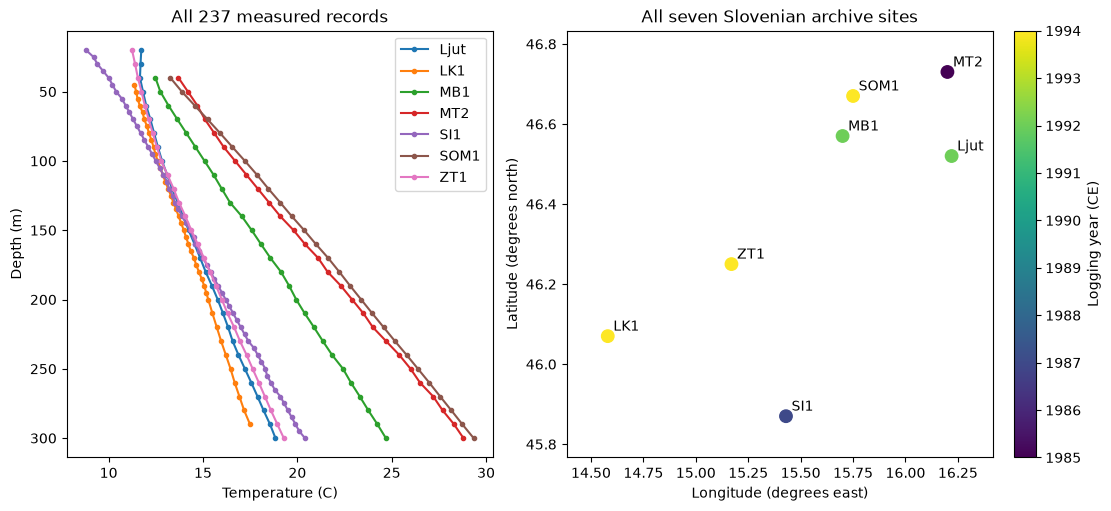

In [2]:
print('Native records:',len(data['depth']),'counts:',data['counts'],'logging years:',data['logging_year'])
data_plot(data);plt.show()

# Physics

Heat diffusion maps a surface-temperature history into a smooth underground profile. At each site, $T=a+bz+Hx+e$, where $T$ is temperature in degrees Celsius, $z$ is positive downward depth in metres, $a$ is the geothermal intercept, $b$ is the geothermal gradient, $x$ is the surface anomaly in kelvin and $e$ is residual error. For elapsed bin boundaries $\tau$, diffusivity $\kappa$ and positive depth,

$$
H_{ij}=\operatorname{erfc}\left(\frac{z_i}{2\sqrt{\kappa\tau_j}}\right)-\operatorname{erfc}\left(\frac{z_i}{2\sqrt{\kappa\tau_{j-1}}}\right).
$$

The zero-time term is zero. The model is a homogeneous conductive half-space; advection, heterogeneous material properties and land-use changes can violate it. Older boundary changes are progressively harder to distinguish. The plots below show the actual operator and its singular values, rather than only a schematic.

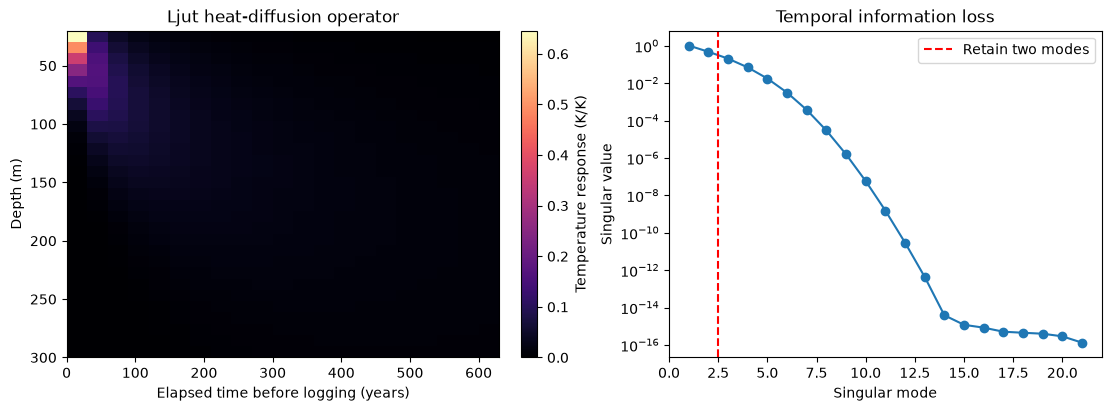

In [3]:
z,_=profiles(data)[0];H=heat_matrix(z);singular=np.linalg.svd(H,compute_uv=False)
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
im=ax[0].imshow(H,aspect='auto',extent=[0,630,z[-1],z[0]],cmap='magma');fig.colorbar(im,ax=ax[0],label='Temperature response (K/K)')
ax[0].set(xlabel='Elapsed time before logging (years)',ylabel='Depth (m)',title='Ljut heat-diffusion operator')
ax[1].semilogy(np.arange(1,22),singular,'o-');ax[1].axvline(2.5,color='r',ls='--',label='Retain two modes');ax[1].legend()
ax[1].set(xlabel='Singular mode',ylabel='Singular value',title='Temporal information loss');plt.show()

# Method

Fit $a,b$ by least squares using the deep measurements, then define the anomaly $y=T-a-bz$. If $H=USV^{\mathsf{T}}$, the selected estimator is $x=V_r S_r^{-1}U_r^{\mathsf{T}}y$ with the first two singular modes retained. This is a direct inverse, so no artificial iterative convergence history is needed. A mode-count study below exposes its stability/fit tradeoff.

The original finite erfc approximation and regression arithmetic are preserved and checked against independent frozen Fortran intermediates. The reference package executes without CIBOR or any domain reconstruction library. This cell actively reconstructs all seven full profiles and writes a fresh benchmark submission.

In [4]:
start=time.perf_counter();fresh=reconstruct(data);runtime=time.perf_counter()-start
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
report=judge.evaluate('output/reconstruction.npz')
Path('output/judge_report.json').write_text(json.dumps(report,indent=2),encoding='utf8')
print('Fresh full reconstruction seconds:',runtime)
print(json.dumps(report,indent=2))
assert report['passed']

Fresh full reconstruction seconds: 0.002307099988684058
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 1.6909584299538166e-14,
    "max_temperature_rmse": 0.08528435353642987
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "max_temperature_rmse": {
      "comparison": "<=",
      "boundary": 0.095
    }
  },
  "errors": []
}


# Results

The paired histories compare the independent original run with a freshly computed local result. Agreement establishes reproduction of this conditional estimator; it does not verify actual climate history. The seven sites have different measurement dates, so their calendar-time axes differ.

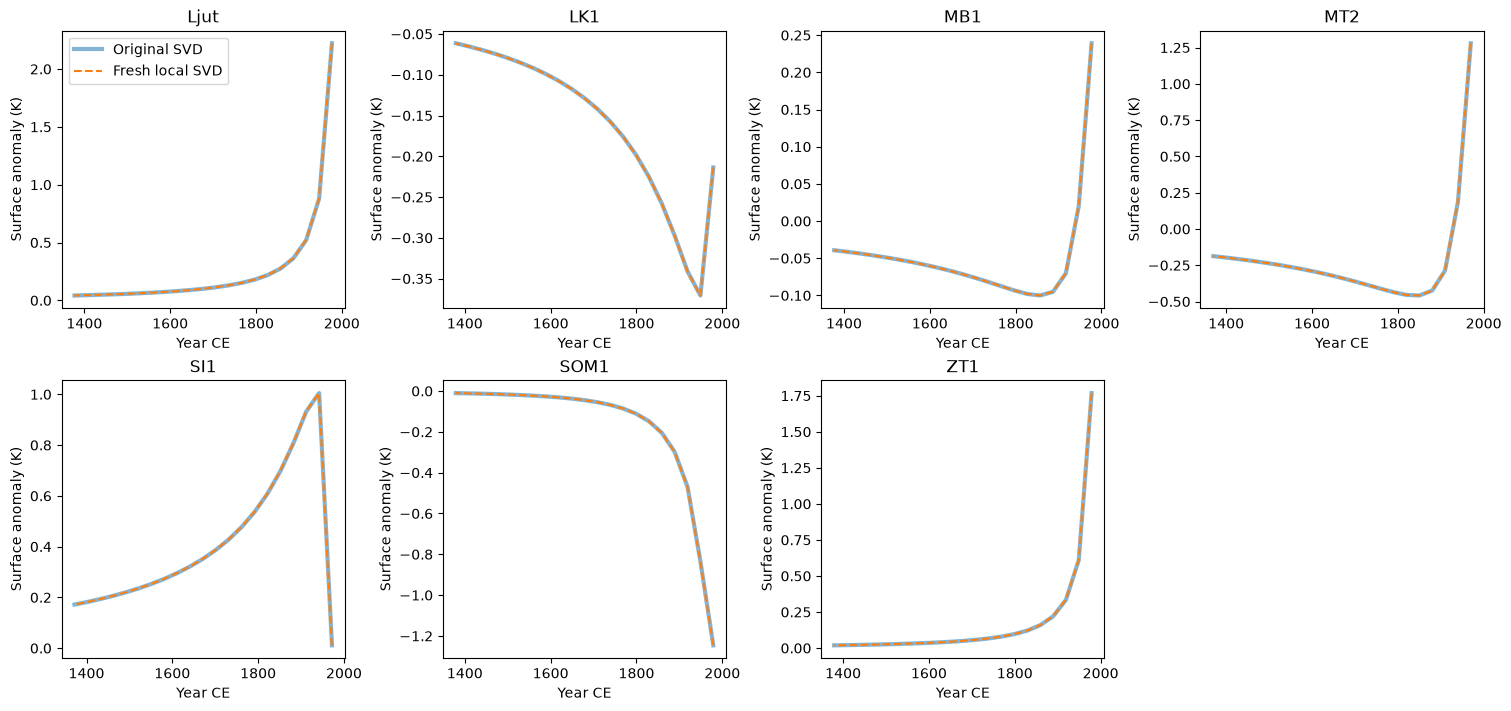

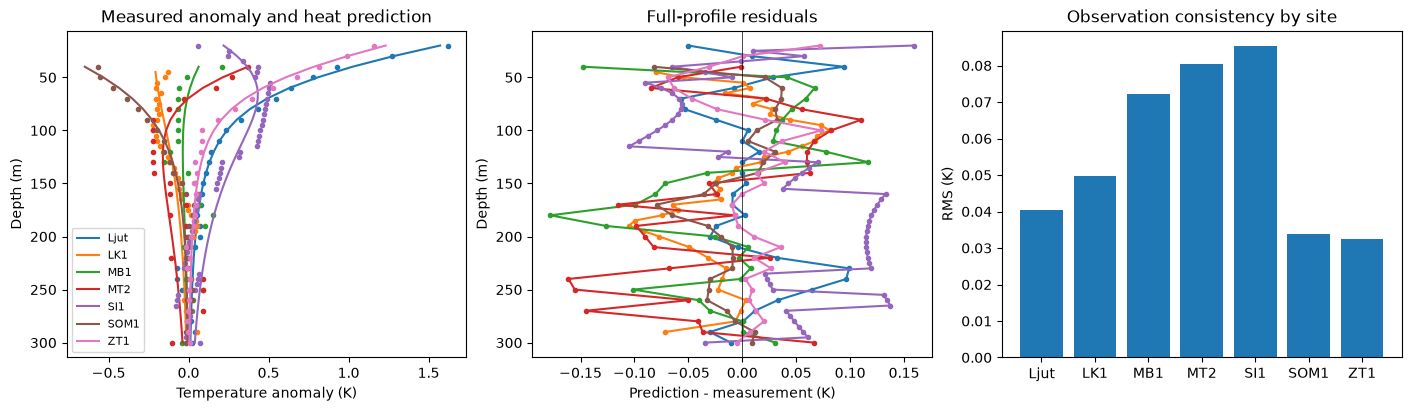

In [5]:
results_plot(data,fresh,reference);plt.show()
residual_plot(data,fresh);plt.show()

## Fresh rank and diffusivity experiments

Each curve below is a new complete seven-site reconstruction. Increasing rank admits poorly constrained temporal modes and can produce large oscillations even when the profile residual improves. Diffusivity uncertainty changes the time-depth relation. The panels use the same sites, observations, bin count and geothermal-background convention.

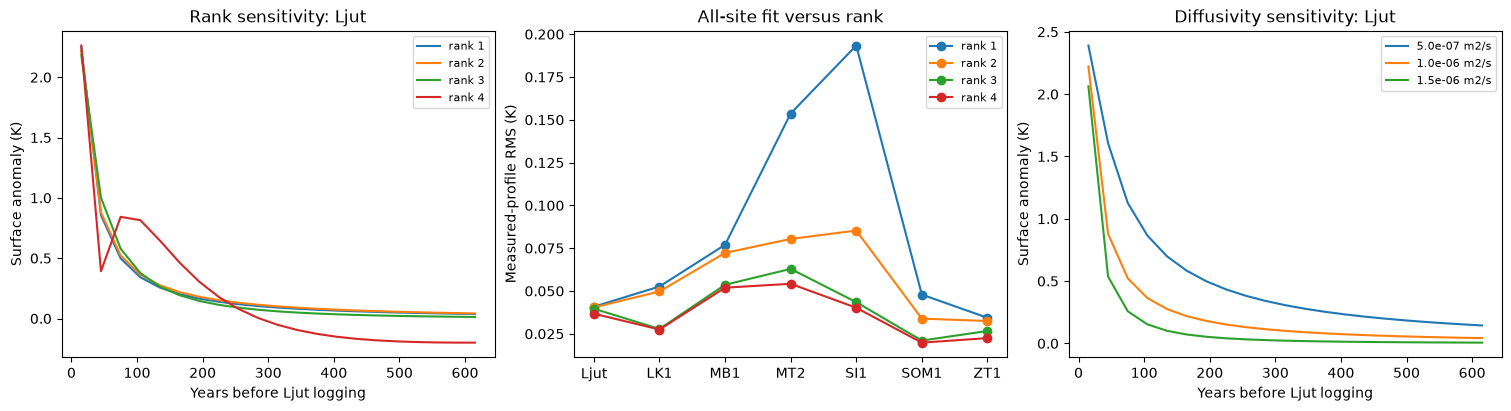

In [6]:
ranks=[1,2,3,4];rank_results={k:reconstruct(data,rank=k) for k in ranks}
diffusivities=[.5e-6,1e-6,1.5e-6];diffusion_results={k:reconstruct(data,diffusivity=k) for k in diffusivities}
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for k,x in rank_results.items():
    axes[0].plot(TIMES-15,x[0],label=f'rank {k}')
    errors=[np.sqrt(np.mean((heat_matrix(z)@x[i]-detrend(z,y)[0][:,1])**2)) for i,(z,y) in enumerate(profiles(data))]
    axes[1].plot(NAMES,errors,'o-',label=f'rank {k}')
for k,x in diffusion_results.items():axes[2].plot(TIMES-15,x[0],label=f'{k:.1e} m2/s')
axes[0].set(xlabel='Years before Ljut logging',ylabel='Surface anomaly (K)',title='Rank sensitivity: Ljut')
axes[1].set(ylabel='Measured-profile RMS (K)',title='All-site fit versus rank')
axes[2].set(xlabel='Years before Ljut logging',ylabel='Surface anomaly (K)',title='Diffusivity sensitivity: Ljut')
for ax in axes:ax.legend(fontsize=8)
plt.show()

## Original paper comparison groups and their limitation

These PPI and BTI curves are **reproduced original outputs on the same bound measured profiles**, read from the author runs, not fresh reconstructions. PPI samples thermal diffusivity and three geothermal perturbations; BTI uses 1000 sampled regional estimates. The paper compares these with the standard SVD method. We preserve that comparison here, while explicitly flagging the implementation's percentile issue. Author text-output rounding is retained, so these displays are not high-precision parity fixtures.

For a simple [0,10] sample, the original weighted quantile routine returns 0 at probability 0.5, while its stated linear interpolation gives 5. Its final expression repeats the lower order statistic in both terms. The original SVD central estimator does not invoke this routine. The original geothermal perturbation widths also are not calibrated confidence intervals. We therefore make no validated coverage claim for the displayed uncertainty bands.

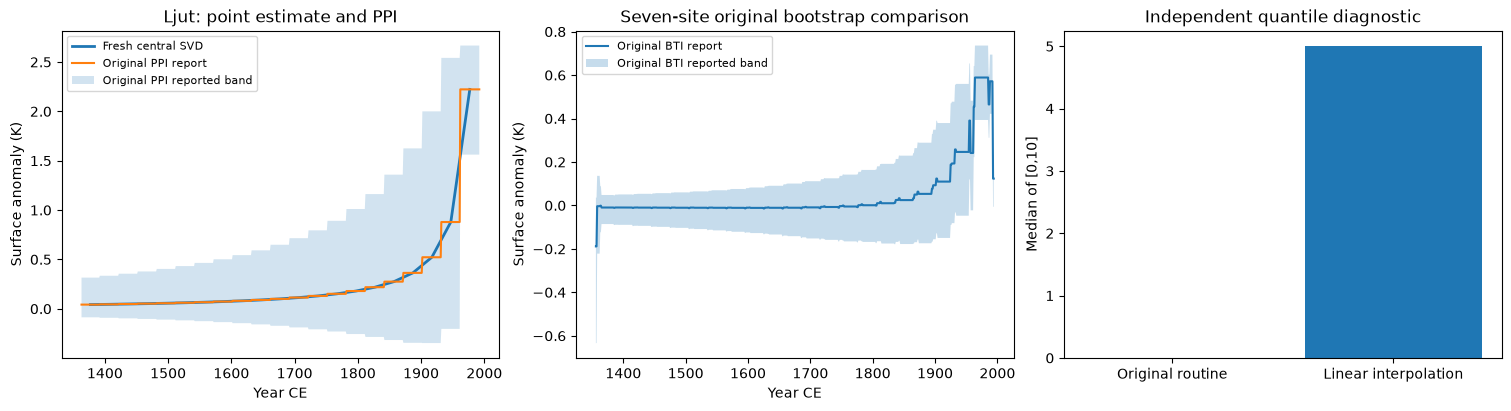

PPI and BTI shown as author reports with known defects; not validated uncertainty estimates.


In [7]:
with np.load('notebooks/reference_outputs/upstream_uncertainty.npz',allow_pickle=False) as a:
    ppi=a['ppi_0'];bti=a['bti']
with np.load('test/fixtures/upstream_quantile_diagnostic.npz',allow_pickle=False) as a:
    sample=a['input_values'];original_median=float(a['output_median'])
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
years=data['logging_year'][0]-(TIMES-15)
axes[0].plot(years,fresh[0],label='Fresh central SVD',lw=2)
axes[0].plot(ppi[:,0],ppi[:,2],label='Original PPI report')
axes[0].fill_between(ppi[:,0],ppi[:,1],ppi[:,3],alpha=.2,label='Original PPI reported band')
axes[0].set(title='Ljut: point estimate and PPI',xlabel='Year CE',ylabel='Surface anomaly (K)');axes[0].legend(fontsize=8)
axes[1].plot(bti[:,0],bti[:,2],label='Original BTI report')
axes[1].fill_between(bti[:,0],bti[:,1],bti[:,3],alpha=.25,label='Original BTI reported band')
axes[1].set(title='Seven-site original bootstrap comparison',xlabel='Year CE',ylabel='Surface anomaly (K)');axes[1].legend(fontsize=8)
axes[2].bar(['Original routine','Linear interpolation'],[original_median,float(np.median(sample))])
axes[2].set(title='Independent quantile diagnostic',ylabel='Median of [0,10]')
plt.show()
print('PPI and BTI shown as author reports with known defects; not validated uncertainty estimates.')

## Fresh author perturbation bounds

This final comparison actively recomputes the standard SVD on the central and two original geothermal perturbations. It visualizes sensitivity to background subtraction without reinterpreting those bounds as confidence levels. Full native depth residuals above provide a separate check; matching another inverse does not establish physical accuracy.

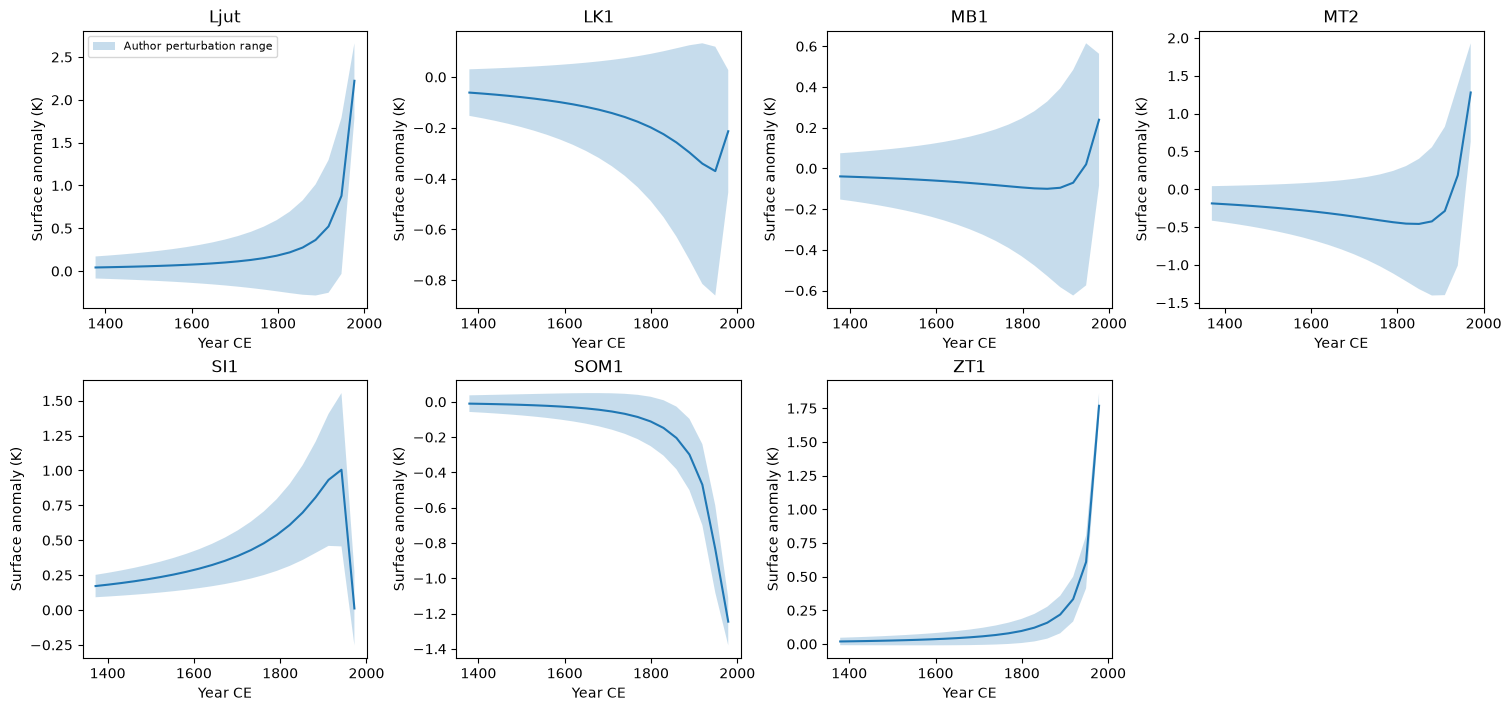

In [8]:
bounds=reconstruct(data,return_bounds=True)
fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
for i,ax in enumerate(axes.flat):
    if i==7:ax.axis('off');continue
    years=data['logging_year'][i]-(TIMES-15)
    ax.fill_between(years,np.min(bounds[i],axis=1),np.max(bounds[i],axis=1),alpha=.25,label='Author perturbation range')
    ax.plot(years,bounds[i,:,1]);ax.set(title=NAMES[i],xlabel='Year CE',ylabel='Surface anomaly (K)')
axes[0,0].legend(fontsize=8);plt.show()
np.savez_compressed('notebooks/reference_outputs/fresh_measurements.npz',runtime_seconds=np.array(runtime),ncc=np.array(report['metrics']['ncc']),nrmse=np.array(report['metrics']['nrmse']),max_temperature_rmse=np.array(report['metrics']['max_temperature_rmse']))

# Conclusion

The complete measured acquisition is actively inverted, the original central SVD estimate is reproduced, and observation residuals pass the fixed consistency boundary. Rank and diffusivity experiments show that acceptable data fits can correspond to different histories. The selected result remains conditional on the conductive half-space, deep-background fit and two-mode regularization.

Original PPI/BTI comparisons have been retained and their percentile defect demonstrated, rather than silently corrected or advertised as verified uncertainty. The benchmark contains no invented historical truth. Future scientific use should investigate site geology, groundwater effects and independently calibrated uncertainty before interpreting the curves as climate measurements.